# 08. Analyze subgroups and wrong predictions

Owner: Gtpatel02. Issue #8. Depends on completed #5.

## Goal

Find where the #5 handoff model (word logistic C4) is weak on the fixed validation set. Save reusable analysis functions so #17 can rerun the same diagnostics on its selected model.

## Setup

Nothing is fitted here. We load the #5 handoff, its saved probabilities, and the fixed split.

To reuse the functions from another notebook without running this analysis, set `ERROR_ANALYSIS_HELPERS_ONLY=1` in the environment, then `%run ./08_error_analysis.ipynb`. The flag is consumed once, like notebook 02's setup flag.

In [1]:
import json, os, time
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython import get_ipython
from sklearn.metrics import roc_auc_score
from threadpoolctl import threadpool_limits
HELPERS_ONLY = os.environ.pop("ERROR_ANALYSIS_HELPERS_ONLY", "0") == "1"
get_ipython().run_line_magic("run", "./02_split_metrics.ipynb")
NAME = "08_error_analysis"
COMMAND = "uv run --locked jupyter nbconvert --execute --to notebook --inplace --ExecutePreprocessor.timeout=900 notebooks/08_error_analysis.ipynb"
CONFIG = {
    "handoff_pointer": "artifacts/05_char_comparison/latest.json",
    "measures": {
        "words": "whitespace-split token count",
        "line_breaks": "count of newline characters",
        "upper_per_letter": "uppercase letters / letters, 0 when no letters",
        "punct_per_char": "characters that are not alphanumeric or whitespace / characters, 0 when empty",
    },
    "bins": "training quartiles at .25/.5/.75, open outer bins, right-closed, repeated edges merged",
    "threshold": 0.5,
    "bootstrap": {"draws": 1000, "seed": SEED, "kind": "class-stratified, resampled within each subgroup",
                  "interval": "2.5 and 97.5 percentiles", "partitions": ["validation"]},
    "cases_per_type": 5,
    "case_order": "FP by highest P(AI), FN by lowest P(AI), ties by ID",
    "reload_tolerance": 1e-12,
}
# Hash source cells only, so the record names the exact committed code, not outputs.
SOURCE_HASH = value_hash(["".join(c["source"]) for c in json.loads((ROOT / "notebooks/08_error_analysis.ipynb").read_text())["cells"]])
CONFIG["notebook_source_sha256"] = SOURCE_HASH
START = time.perf_counter()

## Checks

Recheck the split, the #5 safe record, and every handoff artifact hash. Then recompute validation probabilities with the saved model and confirm they match the saved file. FP means human text predicted AI; FN means AI text predicted human.

In [2]:
if not HELPERS_ONLY:
    parts = load_partitions()
    train, validation = parts["train"], parts["validation"]
    pointer = json.loads((ROOT / CONFIG["handoff_pointer"]).read_text())
    require(pointer["split_sha256"] == parts["split"]["split_sha256"], "Handoff used a different split")
    require(file_hash(ROOT / pointer["result"]) == pointer["result_sha256"], "Handoff record changed")
    for path, expected in pointer["artifacts"].items():
        require(file_hash(ROOT / path) == expected, f"Handoff artifact changed: {path}")
    handoff_record = json.loads((ROOT / pointer["result"]).read_text())
    model = joblib.load(ROOT / pointer["model"])
    saved = {name: pd.read_csv(ROOT / pointer[f"{name}_predictions"], dtype={"id": "string"})
             for name in ["train", "validation"]}
    for name, frame in [("train", train), ("validation", validation)]:
        require(set(saved[name].id) == set(frame.id) and len(saved[name]) == len(frame), f"{name} prediction IDs do not match the split")
    with threadpool_limits(limits=1):
        recomputed = class1_probabilities(model, validation.text)
    aligned = validation[["id"]].merge(saved["validation"], on="id", validate="one_to_one")
    reload_difference = float(np.max(np.abs(aligned.p_ai.to_numpy() - recomputed)))
    require(reload_difference <= CONFIG["reload_tolerance"], "Saved probabilities do not match the handoff model")
    CONFIG["handoff"] = {"result": pointer["result"], "result_sha256": pointer["result_sha256"],
                         "model_sha256": file_hash(ROOT / pointer["model"]), "handoff": pointer["handoff"],
                         "word_family": pointer["word_family"],
                         "handoff_validation_auroc": handoff_record["metrics"]["validation_auroc"]}
    print(f"Handoff: {pointer['handoff']} {pointer['word_family']}; reload difference {reload_difference:.3g}")

Handoff: word logistic; reload difference 1.11e-16


## Method

Four simple measurements per passage. Bin edges come from training quartiles only and are applied unchanged to validation. When quartiles repeat (many texts share a value), the repeated edges merge, so that measure gets fewer bins. Empty and single-class bins are kept and labeled, never dropped or scored as zero.

Each validation bin gets AUROC, accuracy at .5, and a class-stratified bootstrap 95% interval. Training bins get point scores only, since training AUROC is in-sample.

In [3]:
def measure(frame):
    text = frame.text.astype(str)
    letters = text.map(lambda s: sum(c.isalpha() for c in s))
    upper = text.map(lambda s: sum(c.isupper() for c in s))
    punct = text.map(lambda s: sum(not c.isalnum() and not c.isspace() for c in s))
    chars = text.str.len()
    return pd.DataFrame({
        "id": frame.id.to_numpy(),
        "words": text.str.split().str.len().to_numpy(),
        "line_breaks": text.str.count("\n").to_numpy(),
        # Guard empty denominators: no letters or no characters gives 0, not NaN.
        "upper_per_letter": (upper / letters.where(letters > 0)).fillna(0).to_numpy(),
        "punct_per_char": (punct / chars.where(chars > 0)).fillna(0).to_numpy(),
    })

def quartile_edges(values):
    inner = np.unique(np.quantile(np.asarray(values, dtype=float), [.25, .5, .75]))
    return np.concatenate([[-np.inf], inner, [np.inf]])

def stratified_auc_interval(labels, scores, draws=1000, seed=42):
    labels, scores = np.asarray(labels), np.asarray(scores, dtype=float)
    positives, negatives = np.flatnonzero(labels == 1), np.flatnonzero(labels == 0)
    if len(positives) == 0 or len(negatives) == 0:
        return None, None
    rng = np.random.default_rng(seed)
    values = []
    for _ in range(draws):
        # Resample each class separately so every draw keeps both classes.
        idx = np.concatenate([rng.choice(positives, len(positives)), rng.choice(negatives, len(negatives))])
        values.append(roc_auc_score(labels[idx], scores[idx]))
    low, high = np.quantile(values, [.025, .975])
    return float(low), float(high)

def join_rows(frame, predictions, measures):
    joined = frame[["id", "label"]].merge(predictions[["id", "p_ai"]], on="id", validate="one_to_one")
    joined = joined.merge(measures, on="id", validate="one_to_one")
    require(len(joined) == len(frame), "Prediction or measurement rows missing")
    return joined

def subgroup_table(frame, predictions, measures, edges, partition, draws=1000, seed=42):
    joined = join_rows(frame, predictions, measures)
    rows = []
    for column, bins in edges.items():
        groups = pd.cut(joined[column], bins=bins, right=True)
        for interval in groups.cat.categories:
            part = joined[groups == interval]
            row = {"partition": partition, "measure": column, "bin": str(interval), "n": len(part),
                   "human": int((part.label == 0).sum()), "ai": int((part.label == 1).sum())}
            if len(part) == 0:
                row.update(status="empty", auroc=None, accuracy_at_0_5=None, ci_low=None, ci_high=None)
            else:
                metrics = evaluate_predictions(part[["id", "label"]], part[["id", "p_ai"]])
                low, high = stratified_auc_interval(part.label, part.p_ai, draws, seed) if draws else (None, None)
                row.update(status="ok" if metrics["auroc"] is not None else "single_class",
                           auroc=metrics["auroc"], accuracy_at_0_5=metrics["accuracy_at_0_5"],
                           ci_low=low, ci_high=high)
            rows.append(row)
    # Fixed float dtypes keep missing scores as NaN even when a whole column is empty.
    return pd.DataFrame(rows).astype({"auroc": float, "accuracy_at_0_5": float, "ci_low": float, "ci_high": float})

def confident_errors(frame, predictions, measures, threshold=.5, k=5):
    joined = join_rows(frame, predictions, measures)
    predicted_ai = joined.p_ai >= threshold
    fp = joined[predicted_ai & (joined.label == 0)].sort_values(["p_ai", "id"], ascending=[False, True])
    fn = joined[~predicted_ai & (joined.label == 1)].sort_values(["p_ai", "id"], ascending=[True, True])
    counts = {"threshold": threshold, "false_positives": len(fp), "false_negatives": len(fn),
              "true_positives": int((predicted_ai & (joined.label == 1)).sum()),
              "true_negatives": int((~predicted_ai & (joined.label == 0)).sum())}
    cases = pd.concat([fp.head(k).assign(error="FP"), fn.head(k).assign(error="FN")], ignore_index=True)
    columns = ["error", "id", "label", "p_ai", "words", "line_breaks", "upper_per_letter", "punct_per_char"]
    return cases[columns], counts

In [4]:
# Synthetic rows only. These test the analysis code, not the model.
toy = pd.DataFrame({"id": ["a", "b", "c", "d"], "label": [0, 0, 1, 1],
                    "text": ["Hello World.\nok", "123 !!", "one two three", "UP UP\n\nx"]})
toy_measures = measure(toy)
require(toy_measures.words.tolist() == [3, 2, 3, 3], "Word count check failed")
require(toy_measures.line_breaks.tolist() == [1, 0, 0, 2], "Line break check failed")
require(abs(toy_measures.upper_per_letter[0] - 2 / 12) < 1e-12 and toy_measures.upper_per_letter[1] == 0, "Uppercase guard failed")
require(abs(toy_measures.punct_per_char[0] - 1 / 15) < 1e-12, "Punctuation rate failed")
require(quartile_edges([0, 0, 0, 0, 5]).tolist() == [-np.inf, 0, np.inf], "Tied edges should merge")
toy_predictions = pd.DataFrame({"id": ["a", "b", "c", "d"], "p_ai": [.9, .2, .1, .6]})
toy_table = subgroup_table(toy, toy_predictions, toy_measures,
                           {"words": np.array([-np.inf, 2, 3, np.inf])}, "toy", draws=50)
require(toy_table.status.tolist() == ["single_class", "ok", "empty"], "Bin status check failed")
# pandas stores missing scores as NaN; the saved JSON writes them as null.
require(pd.isna(toy_table.auroc[0]) and pd.isna(toy_table.ci_low[0]), "Single-class AUROC must be null")
toy_cases, toy_counts = confident_errors(toy, toy_predictions, toy_measures, k=5)
require(toy_counts == {"threshold": .5, "false_positives": 1, "false_negatives": 1,
                       "true_positives": 1, "true_negatives": 1}, "Error count check failed")
require(len(toy_cases) == 2 and "text" not in toy_cases, "Fewer than five errors must not be padded")
_, edge_counts = confident_errors(toy, toy_predictions.assign(p_ai=[.5, .2, .1, .6]), toy_measures)
require(edge_counts["false_positives"] == 1, "p_ai == threshold counts as predicted AI, same as accuracy")
print("Synthetic analysis checks passed.")

Synthetic analysis checks passed.


## Run

Measure both partitions, derive edges on training, then score every bin. Time the full analysis.

In [5]:
if not HELPERS_ONLY:
    analysis_start = time.perf_counter()
    measures = {"train": measure(train), "validation": measure(validation)}
    edges = {column: quartile_edges(measures["train"][column]) for column in CONFIG["measures"]}
    overall = {}
    for name, frame in [("train", train), ("validation", validation)]:
        overall[name] = evaluate_predictions(frame[["id", "label"]], saved[name])
    joined_validation = join_rows(validation, saved["validation"], measures["validation"])
    overall["validation"]["ci_low"], overall["validation"]["ci_high"] = stratified_auc_interval(
        joined_validation.label, joined_validation.p_ai, CONFIG["bootstrap"]["draws"], SEED)
    tables = pd.concat([
        subgroup_table(train, saved["train"], measures["train"], edges, "train", draws=0),
        subgroup_table(validation, saved["validation"], measures["validation"], edges, "validation",
                       draws=CONFIG["bootstrap"]["draws"], seed=SEED),
    ], ignore_index=True)
    cases, counts = confident_errors(validation, saved["validation"], measures["validation"],
                                     CONFIG["threshold"], CONFIG["cases_per_type"])
    analysis_seconds = time.perf_counter() - analysis_start

## Results

Validation intervals condition on the fitted handoff and the reused 2,000 validation rows. They do not cover training variation or the model choice made in #4.

,partition,rows,auroc,accuracy_at_0_5,ci_low,ci_high
0,train,8000,0.999925,0.9925,NaN,NaN
1,validation,2000,0.941252,0.8780,0.93052,0.950925


Train minus validation AUROC: 0.058673
Bins per measure: {'words': 4, 'line_breaks': 4, 'upper_per_letter': 4, 'punct_per_char': 4}


,measure,bin,n,human,ai,status,auroc,accuracy_at_0_5,ci_low,ci_high,train_auroc
0,words,"(-inf, 160.0]",471,196,275,ok,0.912004,0.830149,0.887438,0.935591,0.999850
1,words,"(160.0, 206.0]",531,322,209,ok,0.920354,0.890772,0.890405,0.947446,0.999924
2,words,"(206.0, 256.0]",503,277,226,ok,0.966023,0.904573,0.949218,0.979684,0.999964
3,words,"(256.0, inf]",495,205,290,ok,0.960791,0.882828,0.946070,0.972835,0.999955
4,line_breaks,"(-inf, 0.0]",598,330,268,ok,0.954376,0.892977,0.938262,0.969053,0.999976
5,line_breaks,"(0.0, 4.0]",390,251,139,ok,0.908940,0.871795,0.872365,0.940498,0.999880
6,line_breaks,"(4.0, 13.0]",518,223,295,ok,0.952527,0.876448,0.932443,0.967624,0.999970
7,line_breaks,"(13.0, inf]",494,196,298,ok,0.940710,0.866397,0.921182,0.958571,0.999889
8,upper_per_letter,"(-inf, 0.0181]",492,225,267,ok,0.980125,0.932927,0.969536,0.989315,0.999959
9,upper_per_letter,"(0.0181, 0.028]",474,224,250,ok,0.957036,0.886076,0.937286,0.971967,0.999970


Confusion at threshold .5: {'threshold': 0.5, 'false_positives': 61, 'false_negatives': 183, 'true_positives': 817, 'true_negatives': 939}


,error,id,label,p_ai,words,line_breaks,upper_per_letter,punct_per_char
0,FP,8785,0,0.755218,157,0,0.024946,0.027580
1,FP,968,0,0.740957,202,18,0.015113,0.018987
2,FP,7211,0,0.703038,140,0,0.019200,0.015464
3,FP,5583,0,0.689024,322,3,0.025958,0.018696
4,FP,4409,0,0.669008,229,0,0.035985,0.033860
5,FN,679,1,0.056918,205,8,0.060364,0.021467
6,FN,3062,1,0.084843,170,6,0.022693,0.027972
7,FN,8309,1,0.089665,256,11,0.121993,0.032916
8,FN,8788,1,0.095248,121,12,0.021773,0.027363
9,FN,2387,1,0.102745,197,4,0.055621,0.030675


Analysis runtime: 7.985 seconds


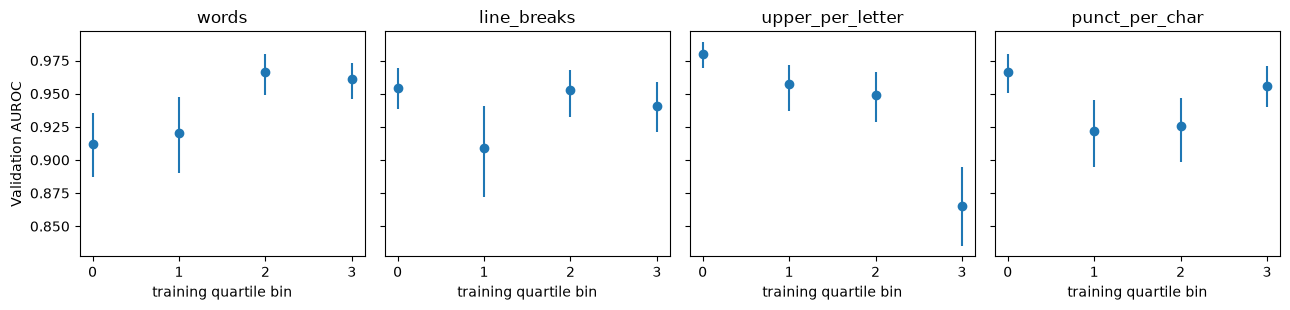

In [6]:
if not HELPERS_ONLY:
    display(pd.DataFrame([{"partition": name, "rows": m["rows"], "auroc": m["auroc"],
                           "accuracy_at_0_5": m["accuracy_at_0_5"],
                           "ci_low": m.get("ci_low"), "ci_high": m.get("ci_high")} for name, m in overall.items()]))
    print(f"Train minus validation AUROC: {overall['train']['auroc'] - overall['validation']['auroc']:.6f}")
    print("Bins per measure:", {column: len(bins) - 1 for column, bins in edges.items()})
    gap = tables.pivot_table(index=["measure", "bin"], columns="partition", values="auroc", sort=False)
    display(tables[tables.partition == "validation"].drop(columns="partition").merge(
        gap.rename(columns={"train": "train_auroc"})[["train_auroc"]].reset_index(), on=["measure", "bin"]))
    print("Confusion at threshold .5:", counts)
    display(cases)
    print(f"Analysis runtime: {analysis_seconds:.3f} seconds")
    fig, axes = plt.subplots(1, len(edges), figsize=(13, 3.2), sharey=True)
    for ax, column in zip(axes, edges):
        part = tables[(tables.partition == "validation") & (tables.measure == column) & (tables.status == "ok")]
        ax.errorbar(range(len(part)), part.auroc, yerr=[part.auroc - part.ci_low, part.ci_high - part.auroc], fmt="o")
        ax.set(title=column, xticks=range(len(part)), xlabel="training quartile bin")
    axes[0].set_ylabel("Validation AUROC")
    fig.tight_layout()
    plot_path = ROOT / "results" / NAME / f"{datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')}-subgroups.png"
    plot_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(plot_path, dpi=140)
    plt.show()

## Error hypotheses

Ten most confident errors at threshold .5. Five of each type exist, so nothing is padded. I read these passages privately; only IDs, probabilities, and measurements are shown. The last column is a guess, not a measurement.

| Type | ID | P(AI) | What I saw | Guess |
|---|---|---:|---|---|
| FP | 8785 | 0.755 | Organization profile, dense with names and counts, no line breaks | Polished promo register looks like AI to word features |
| FP | 968 | 0.741 | Academic abstract, hard-wrapped (18 line breaks) | Formal abstract register; word tokens cannot see the wrapping |
| FP | 7211 | 0.703 | Casual forum post with typos | Unclear. Maybe topic words common in AI training rows |
| FP | 5583 | 0.689 | News report with quotes, 322 words | Neutral news register reads as generated |
| FP | 4409 | 0.669 | Film review built on repeated parallel sentences, missing spaces after periods | Repetition looks generated; the typo pattern is lost after tokenizing |
| FN | 679 | 0.057 | Encyclopedia-style place history with names and years | AI imitating a genre that is common in human rows |
| FN | 3062 | 0.085 | First-person forum post, blank lines between paragraphs, curly apostrophes | Casual human-like voice; formatting dropped by word tokens |
| FN | 8309 | 0.090 | Institutional history, acronyms, citation marker, blank line; top uppercase quartile | Encyclopedia imitation |
| FN | 8788 | 0.095 | Math abstract, hard wraps, indented lines, LaTeX | Same abstract layout as FP 968, so layout likely comes from the source |
| FN | 2387 | 0.103 | Biography dense with dates and ranks, blank line | Encyclopedia imitation |

**Observed, measured on all 2,000 rows.** The highest uppercase quartile is weakest (AUROC 0.865, CI 0.835 to 0.895). The lowest uppercase quartile is strongest (0.980, CI 0.970 to 0.989), and the two intervals do not overlap. The shortest quartile (160 words or fewer) is 0.912. Errors at .5 are lopsided: 61 FP vs 183 FN. Training AUROC is at least 0.9998 in every bin.

**Observed, only in these ten.** Three of five FN contain a blank line (two newlines in a row); none of the five FP do. Three of five FN look encyclopedia-style. Ten rows are too few to call these patterns.

**Speculation.** The model may lean on genre vocabulary more than on authorship. High uppercase may stand in for name-dense encyclopedic text. Formatting such as blank lines and hard wraps is invisible to the word tokenizer. Hidden test domains and generators are unknown, so none of this proves why Kaggle errors happen.

## Takeaway

- Tried: four training-quartile subgroups, bootstrap intervals, and the ten most confident errors for the word C4 handoff.
- Found: near-perfect training AUROC but 0.941 on validation (gap 0.059). Weakest spots are high-uppercase and short texts. FN outnumber FP three to one at .5.
- Next: #9 tests a small style feature block aimed at the high-uppercase and short-text bins, with its adoption rule fixed before running. Blank lines in the FN are a lead for #11, not a result.

## Save

One safe record in `results/08_error_analysis/`. It holds bin edges, subgroup tables, counts, and the ten required error rows (ID, probability, measurements). No passage text or full prediction files are saved. Nothing is fitted, so `fit_rows` is 0.

In [7]:
if not HELPERS_ONLY:
    metrics = {"validation_auroc": overall["validation"]["auroc"], "overall": overall,
               "train_minus_validation_auroc": overall["train"]["auroc"] - overall["validation"]["auroc"],
               "edges": {column: [None if not np.isfinite(x) else float(x) for x in bins] for column, bins in edges.items()},
               "subgroups": json.loads(tables.to_json(orient="records")),
               "confusion_at_threshold": counts, "error_cases": json.loads(cases.to_json(orient="records")),
               "reload_difference": reload_difference, "analysis_seconds": analysis_seconds}
    CONFIG["extra_versions"] = {name: importlib.metadata.version(name) for name in ["joblib", "matplotlib", "threadpoolctl"]}
    record_path = record_run(NAME, COMMAND, CONFIG, SEED, 0, len(validation), metrics,
                             time.perf_counter() - START, artifacts=[plot_path])
    print(f"Saved {record_path.relative_to(ROOT)}")

Saved results/08_error_analysis/20261110T191604750902Z.json
